# 03 — Exploratory Data Analysis

Business question: **Why are customers leaving?** Focus on rates and decisions, not chart quantity.

In [5]:
from pathlib import Path
import sys, pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd().resolve()
if not (ROOT/"src").exists(): ROOT = ROOT.parent
sys.path.append(str(ROOT))
DATA = ROOT/"data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
assert DATA.exists(), f"Download the dataset and place it at {DATA}"

from src.data_cleaning import clean_data, prepare_target
from src.feature_engineering import add_business_features
df=add_business_features(prepare_target(clean_data(pd.read_csv(DATA))))
print(f"Overall churn rate: {df.Churn.mean():.2%}")

Overall churn rate: 26.54%


In [6]:
def churn_summary(col):
    x=df.groupby(col).Churn.agg(['count','sum','mean']).reset_index(); x['churn_rate_pct']=100*x['mean']; return x.sort_values('churn_rate_pct',ascending=False)
for c in ['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity']:
    print('\n',c); display(churn_summary(c))
df['TenureGroup']=pd.cut(df.tenure,[-1,12,24,48,np.inf],labels=['0-12','13-24','25-48','49+']); display(churn_summary('TenureGroup'))


 Contract


,Contract,count,sum,mean,churn_rate_pct
0,Month-to-month,3875,1655,0.427097,42.709677
1,One year,1473,166,0.112695,11.269518
2,Two year,1695,48,0.028319,2.831858



 InternetService


,InternetService,count,sum,mean,churn_rate_pct
1,Fiber optic,3096,1297,0.418928,41.892765
0,DSL,2421,459,0.189591,18.959108
2,No,1526,113,0.074050,7.404980



 PaymentMethod


...

,TechSupport,count,sum,mean,churn_rate_pct
0,No,3473,1446,0.416355,41.635474
2,Yes,2044,310,0.151663,15.166341
1,No internet service,1526,113,0.074050,7.404980



 OnlineSecurity


,OnlineSecurity,count,sum,mean,churn_rate_pct
0,No,3498,1461,0.417667,41.766724
2,Yes,2019,295,0.146112,14.611194
1,No internet service,1526,113,0.074050,7.404980


C:\Users\SAYAN PANDA\AppData\Local\Temp\ipykernel_19404\1074252019.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  x=df.groupby(col).Churn.agg(['count','sum','mean']).reset_index(); x['churn_rate_pct']=100*x['mean']; return x.sort_values('churn_rate_pct',ascending=False)


,TenureGroup,count,sum,mean,churn_rate_pct
0,0-12,2186,1037,0.474382,47.438243
1,13-24,1024,294,0.287109,28.710938
2,25-48,1594,325,0.203890,20.388959
3,49+,2239,213,0.095132,9.513176


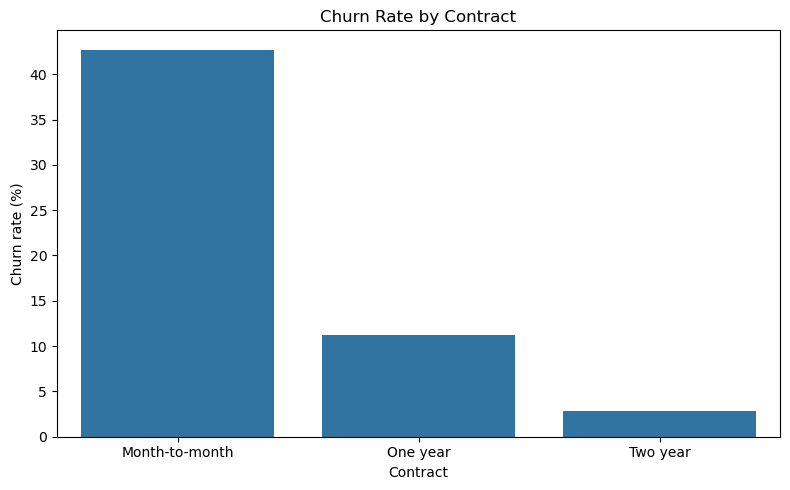

In [7]:
plt.figure(figsize=(8,5)); sns.barplot(data=churn_summary('Contract'),x='Contract',y='churn_rate_pct'); plt.ylabel('Churn rate (%)'); plt.title('Churn Rate by Contract'); plt.tight_layout(); plt.savefig(ROOT/'images/eda/churn_by_contract.png',dpi=160); plt.show()

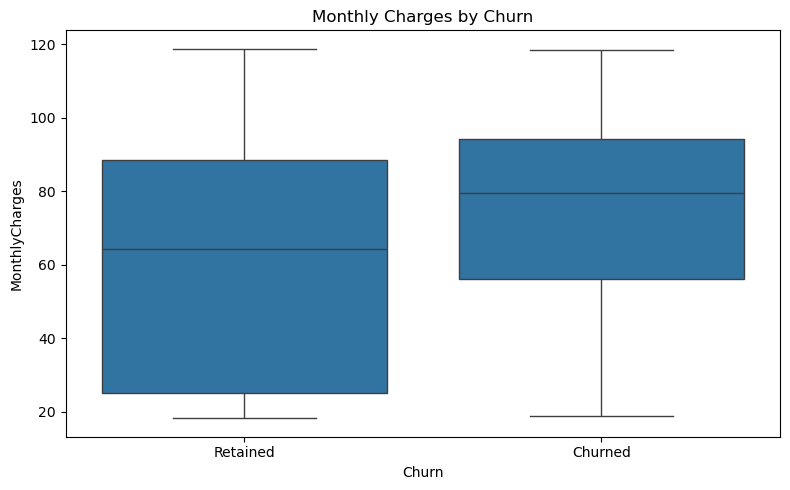

In [8]:
plt.figure(figsize=(8,5)); sns.boxplot(data=df,x='Churn',y='MonthlyCharges'); plt.xticks([0,1],['Retained','Churned']); plt.title('Monthly Charges by Churn'); plt.tight_layout(); plt.savefig(ROOT/'images/eda/monthly_charges_by_churn.png',dpi=160); plt.show()